   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.7/225.7 kB 4.9 MB/s eta 0:00:00
=== ENV_LOG v1.0 | MODE = FAST | Lieu = Paris ===
  Estimations : 1 | Fenêtre : 90j | Test : cohen_d
  Seuil critique (hypothèse) : 70.0e percentile

Gradient d'anomalie : 28 points

[1/6] Téléchargement des données climatiques...
[Open-Meteo] Téléchargement Paris (2010-01-01 → 2024-12-31)...
[OK] 5479 jours | 2010-01-01 → 2024-12-31
     Valeurs manquantes : 0 cellules

[2/6] Scan du seuil critique (50–85e percentile)...


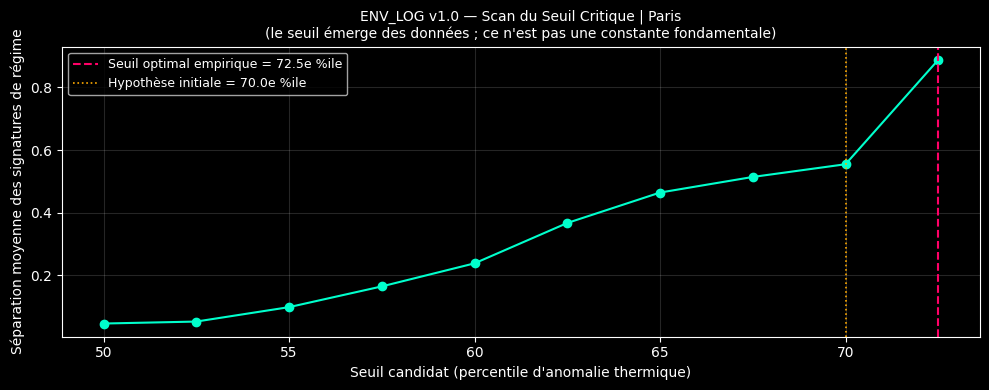


[Scan du seuil critique]
  Hypothèse initiale           : 70.0e percentile
  Seuil optimal (données)      : 72.5e percentile  (séparation = 0.888)
  Note : robuste si la courbe ci-dessus présente un plateau stable.

[3/6] Vue d'ensemble climatique...


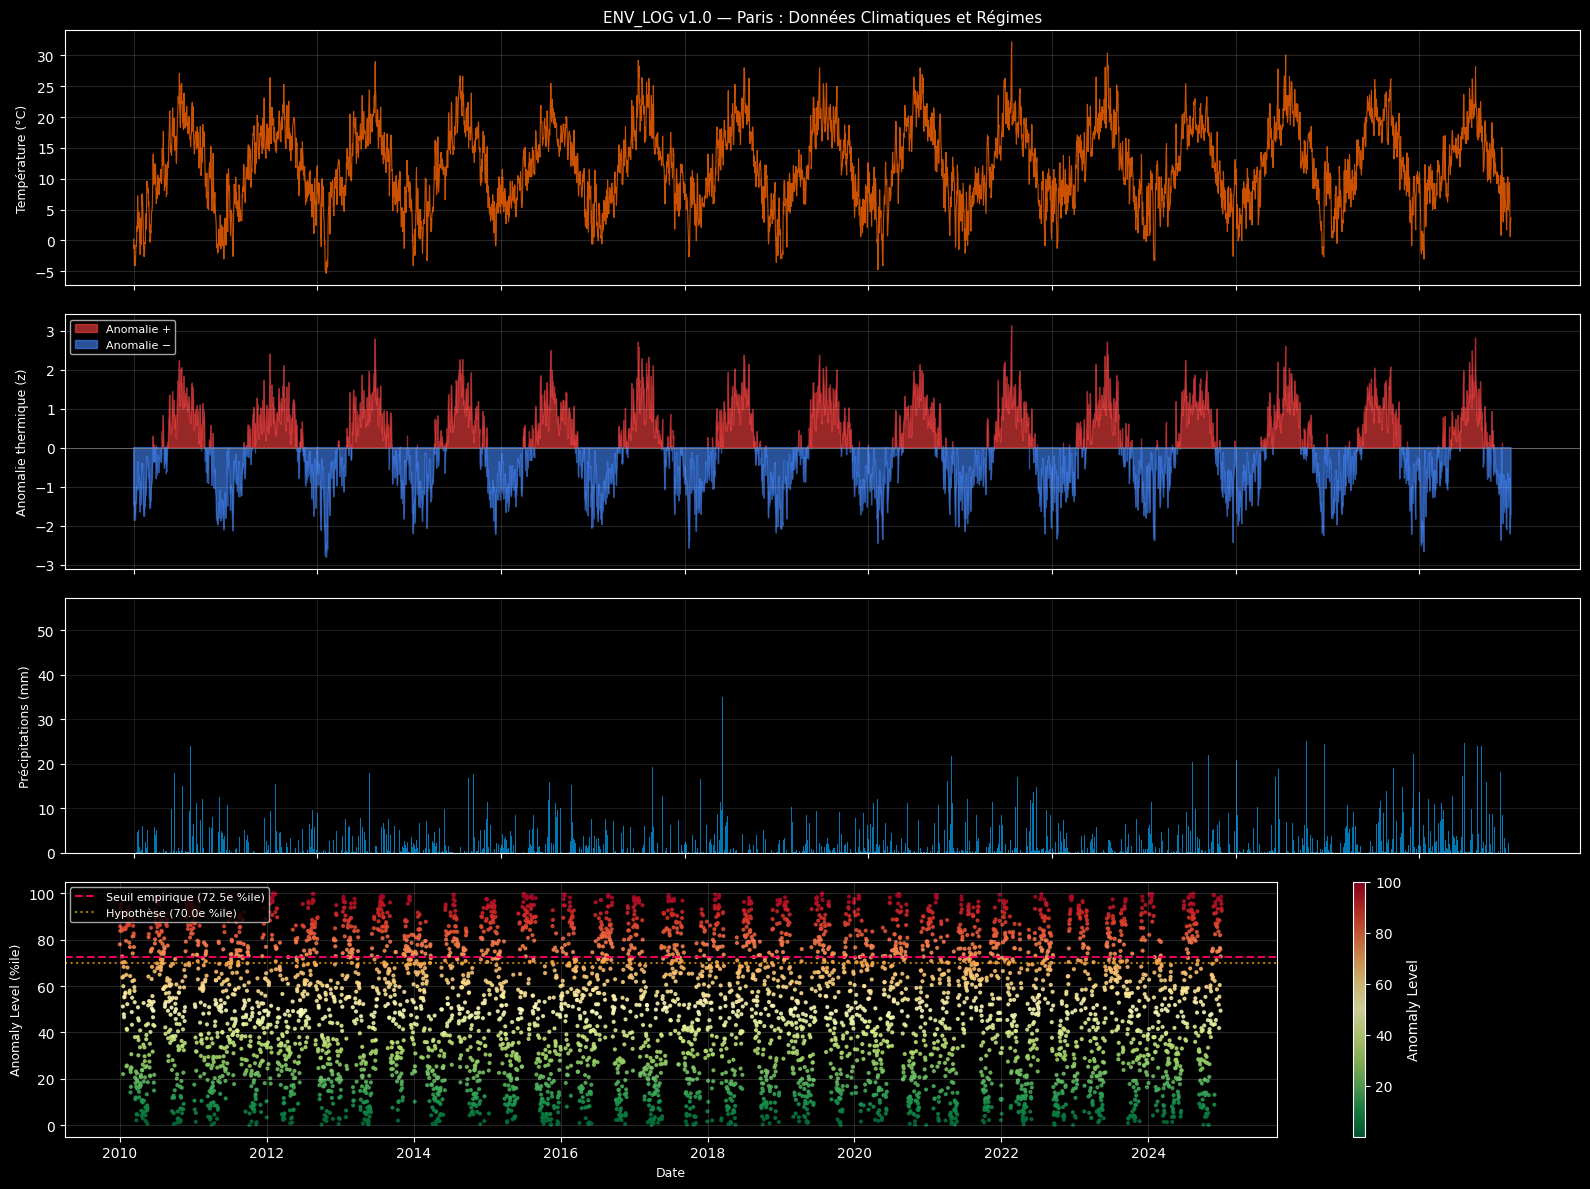


[4/6] Profils des 5 flux environnementaux...


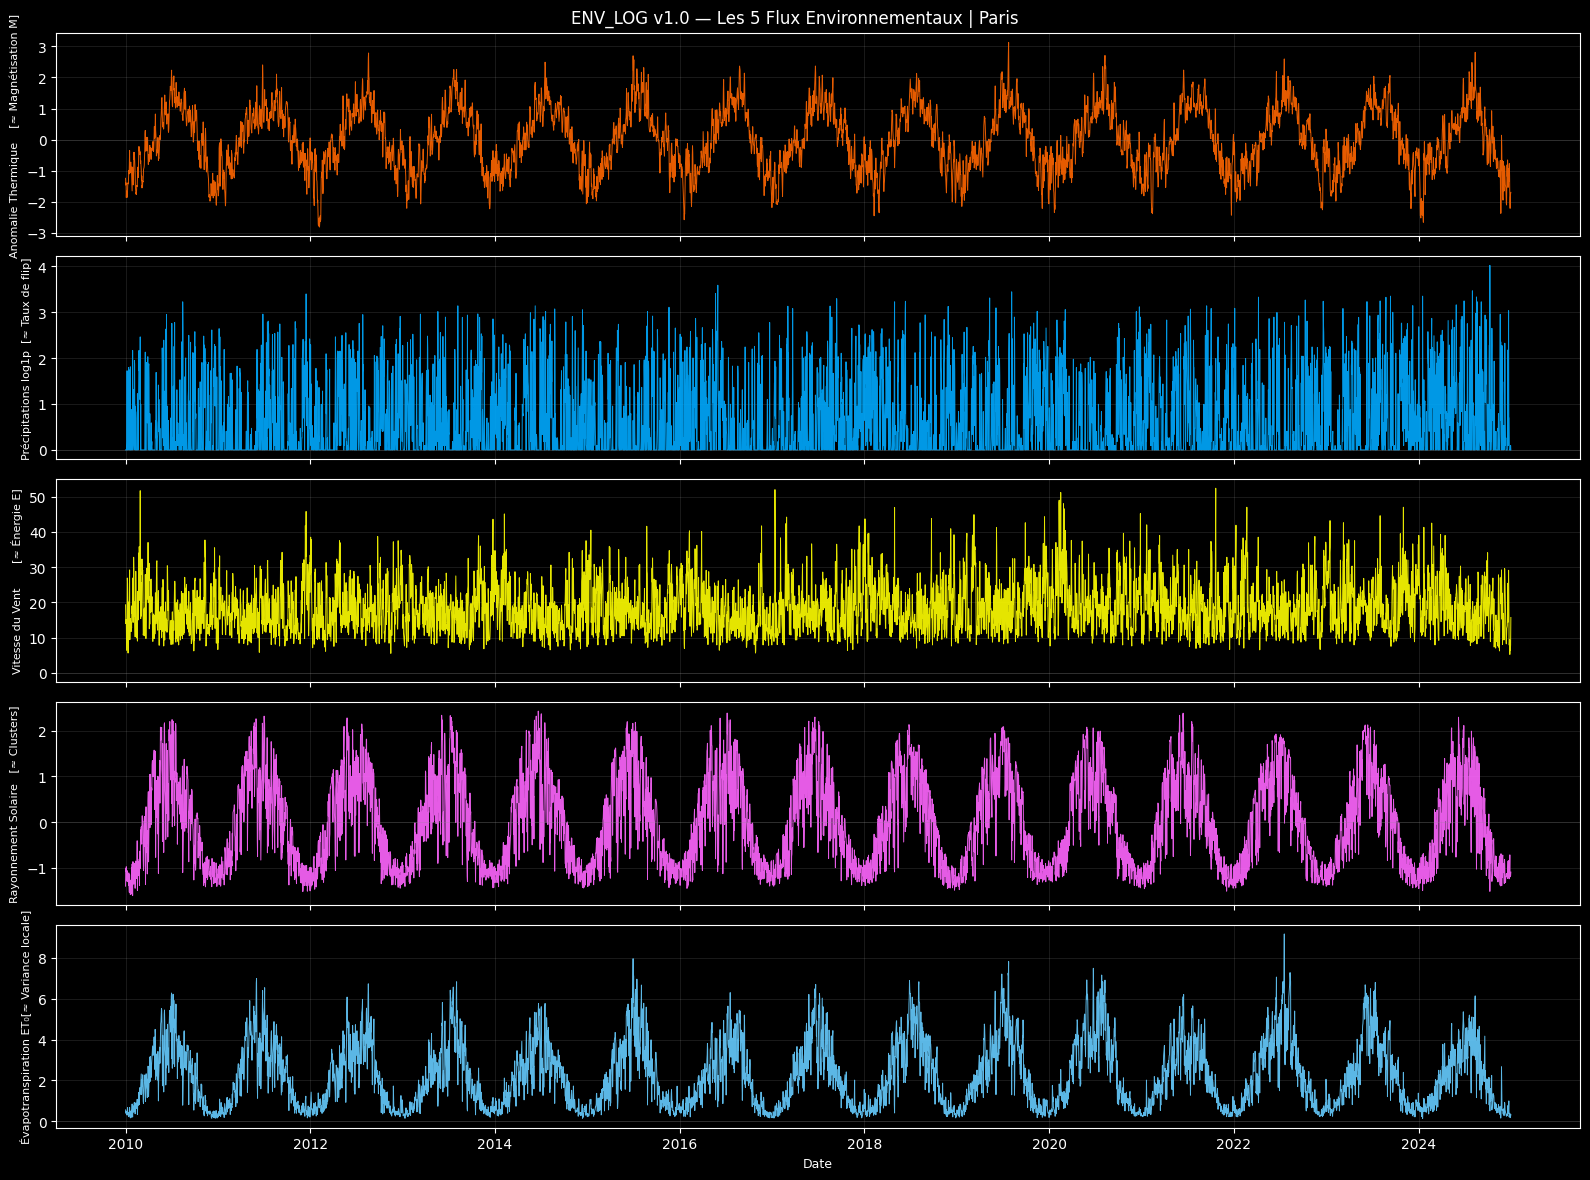


[5/6] Extraction des signatures de régime...

[Extraction des signatures de régime] 1 réalisation unique | Fenêtre=90j


Scan d'anomalie: 100%|██████████| 28/28 [16:27<00:00, 35.25s/it]


  Signatures extraites : 25
   Anomaly  N_windows  Temp_Anomaly_Higuchi_mean  Temp_Anomaly_DFA_mean  Temp_Anomaly_Katz_mean  Temp_Anomaly_Hurst_mean
0      5.0          1                   1.819621               0.851944                2.194233                 0.696781
1     10.0          1                   1.819621               0.851944                2.194233                 0.635345
2     15.0          1                   1.819621               0.851944                2.194233                 0.696781


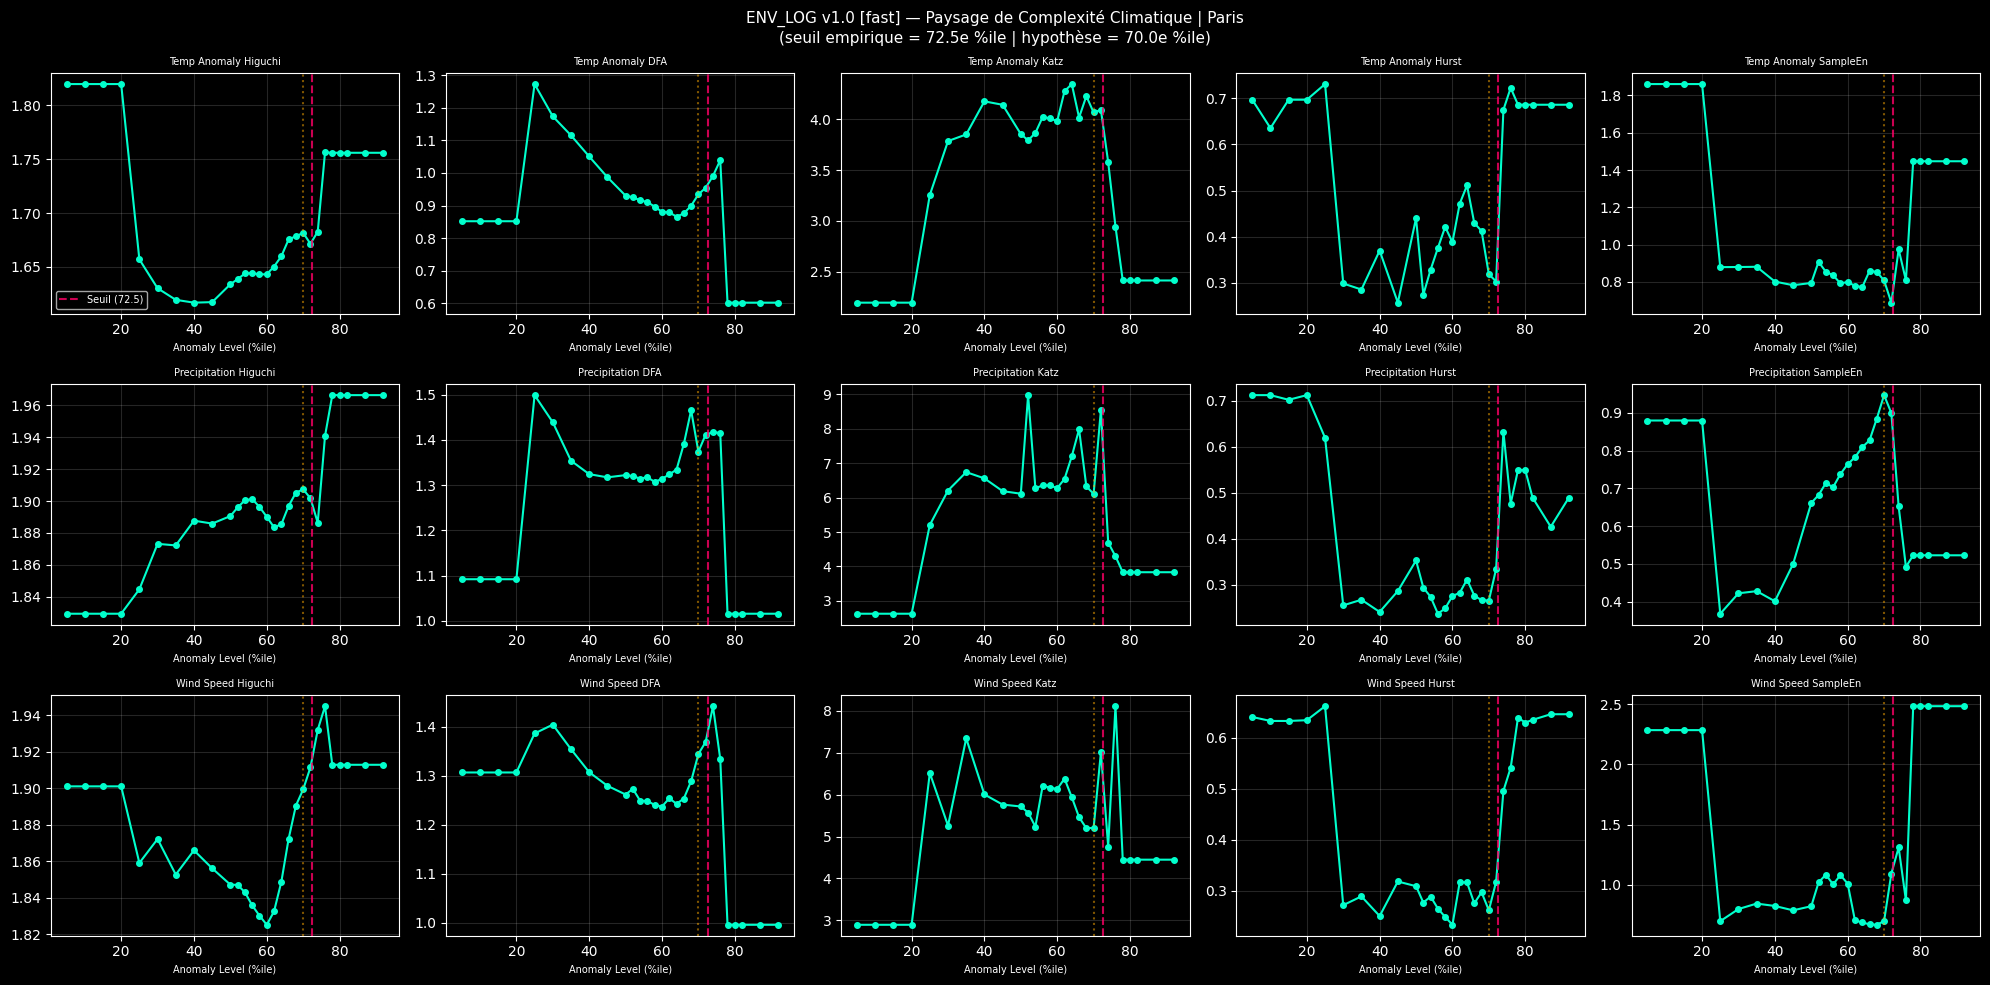


[6/6] 4 Questions environnementales...

=== 4 Questions Environnementales (seuil empirique = 72.5e %ile) ===
Q1 : Régime Stable vs Régime Perturbé (anomalie faible vs forte)...
Q2 : Tension au Seuil Critique (zone de transition de régime)...
Q3 : Calme vs Turbulence (signatures dynamiques — vent + précipitations)...
Q4 : Persistance de Régime (hystérésis intra-fenêtre)...

>>> RÉSULTATS — Scores de séparation des signatures de régime :
                                  Q1_Stable_vs_Perturbe  Q2_Tension_Critique  Q3_Calme_vs_Turbulence  Q4_Persistance_Regime
Evapotranspiration_DFA_mean                       1.155                3.115                   0.332                  1.300
Evapotranspiration_Higuchi_mean                   0.868                0.490                   1.298                  1.300
Evapotranspiration_Hurst_mean                     2.882                4.908                   1.837                  1.300
Evapotranspiration_Katz_mean                      4.409        

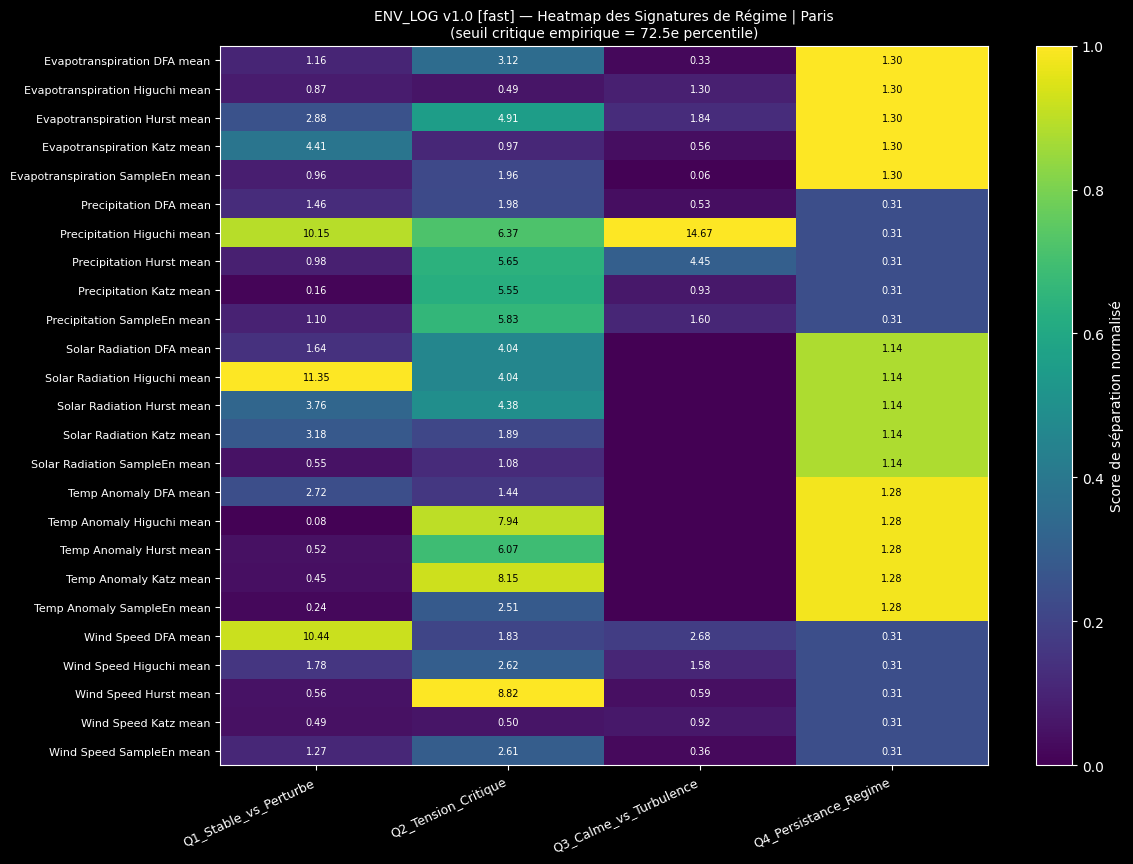


[OK] ENV_LOG v1.0 terminé. | Paris | Seuil empirique : 72.5e percentile


In [1]:
!pip install -q nolds antropy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy import stats
import requests
import warnings
warnings.filterwarnings('ignore')
import antropy, nolds

plt.style.use('dark_background')

# =============================================================================
# ENV_LOG v1.0 — Analyse de Complexité pour Séries Temporelles Climatiques
# =============================================================================
# Source : Open-Meteo Historical Archive API (gratuit, sans clé, mondial)
#
# Paramètre de contrôle : percentile de l'anomalie thermique absolue
#   → Anomalie faible  = conditions normales (régime stable / ordonné)
#   → Anomalie forte   = conditions extrêmes (régime perturbé / désordonné)
#
# SEUIL CRITIQUE (TEMP_CRITIQUE_HYPOTHESE) :
#   Il n'existe pas de Tc analytique en climatologie locale. Le seuil est
#   une HYPOTHÈSE DE TRAVAIL. La fonction scan_seuil_critique() teste la
#   plage 50–85 % et laisse le seuil émerger des données.
#
# MODE ROBUST — "n_estimations" :
#   Le climat n'a eu lieu qu'une fois. Le bootstrap sur sous-fenêtres est
#   une ESTIMATION DE STABILITÉ STATISTIQUE, pas une simulation de
#   chronologies climatiques alternatives.
#
# 5 FLUX ENVIRONNEMENTAUX :
#   1. Temp_Anomaly      : z-score rolling de T°          [≈ Magnétisation M]
#   2. Precipitation     : cumul journalier (mm)          [≈ Taux de flip]
#   3. Wind_Speed        : vitesse max journalière (km/h) [≈ Énergie E]
#   4. Solar_Radiation   : rayonnement SW (MJ/m²)         [≈ Taille des clusters]
#   5. Evapotranspiration: ET₀ FAO journalier (mm)        [≈ Variance locale]
# =============================================================================

# --- CONFIGURATION GÉOGRAPHIQUE (modifiable) ---
LATITUDE  = 48.8566    # Paris
LONGITUDE = 2.3522
LIEU_NOM  = "Paris"
START_DATE = "2010-01-01"
END_DATE   = "2024-12-31"

TEMP_CRITIQUE_HYPOTHESE = 70.0   # hypothèse de travail : 70e percentile d'anomalie
MODE = 'fast'                     # 'fast' ou 'robust'

CONFIG = {
    'fast': {
        'n_estimations': 1,
        'window_size': 90,          # fenêtre de 90 jours ≈ 1 saison
        'stat_test': 'cohen_d',
        'min_per_group': 2,
        'estimator_min_len': 60,
        'mann_whitney': False,
        'bootstrap': False,
    },
    'robust': {
        'n_estimations': 5,
        'window_size': 180,
        'stat_test': 'cliff_delta',
        'min_per_group': 3,
        'estimator_min_len': 120,
        'mann_whitney': True,
        'bootstrap': True,
    }
}
C = CONFIG[MODE]
print(f"=== ENV_LOG v1.0 | MODE = {MODE.upper()} | Lieu = {LIEU_NOM} ===")
print(f"  Estimations : {C['n_estimations']} | Fenêtre : {C['window_size']}j | Test : {C['stat_test']}")
print(f"  Seuil critique (hypothèse) : {TEMP_CRITIQUE_HYPOTHESE}e percentile")

# =============================================================================
# 0. STATISTIQUES
# =============================================================================

def cohen_d(g1, g2):
    g1, g2 = np.asarray(g1), np.asarray(g2)
    if len(g1) < 2 or len(g2) < 2:
        return np.nan
    pooled_std = np.sqrt((np.var(g1, ddof=1) + np.var(g2, ddof=1)) / 2.0)
    return 0.0 if pooled_std < 1e-12 else (np.mean(g1) - np.mean(g2)) / pooled_std

def cliff_delta(g1, g2):
    g1, g2 = np.asarray(g1), np.asarray(g2)
    n1, n2 = len(g1), len(g2)
    if n1 < C['min_per_group'] or n2 < C['min_per_group']:
        return np.nan, np.nan
    try:
        U, _ = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        return np.clip((2 * U - n1 * n2) / (n1 * n2), -1, 1), np.nan
    except:
        return np.nan, np.nan

def separation_score(g1, g2):
    if C['stat_test'] == 'cohen_d':
        d = cohen_d(g1, g2)
        return abs(d) if not np.isnan(d) else np.nan
    else:
        d, _ = cliff_delta(g1, g2)
        return abs(d) if not np.isnan(d) else np.nan

def mw_score(g1, g2):
    if not C['mann_whitney']:
        return np.nan
    try:
        _, p = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        return -np.log10(max(p, 1e-300))
    except:
        return np.nan

# =============================================================================
# 1. ACQUISITION — Open-Meteo Historical Archive (sans clé API)
# =============================================================================

def fetch_climate_data(lat, lon, start, end, lieu=''):
    """
    Télécharge les données météo journalières via Open-Meteo Historical Archive.
    API publique, sans clé, sans restriction géographique.
    Résolution : journalière | Couverture : monde entier | Historique : 1940–hier
    """
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        'latitude':  lat,
        'longitude': lon,
        'start_date': start,
        'end_date':   end,
        'daily': ','.join([
            'temperature_2m_mean',
            'precipitation_sum',
            'wind_speed_10m_max',
            'shortwave_radiation_sum',
            'et0_fao_evapotranspiration'
        ]),
        'timezone': 'auto'
    }
    print(f"[Open-Meteo] Téléchargement {lieu} ({start} → {end})...")
    resp = requests.get(url, params=params, timeout=60)
    resp.raise_for_status()
    data = resp.json()['daily']

    df = pd.DataFrame({
        'Date':               pd.to_datetime(data['time']),
        'Temperature':        data['temperature_2m_mean'],
        'Precipitation':      data['precipitation_sum'],
        'Wind_Speed':         data['wind_speed_10m_max'],
        'Solar_Radiation':    data['shortwave_radiation_sum'],
        'Evapotranspiration': data['et0_fao_evapotranspiration'],
    })
    for col in ['Temperature','Precipitation','Wind_Speed','Solar_Radiation','Evapotranspiration']:
        df[col] = pd.to_numeric(df[col], errors='coerce')

    # Interpolation des valeurs manquantes (rares dans Open-Meteo)
    df[['Precipitation','Wind_Speed','Solar_Radiation','Evapotranspiration']] = (
        df[['Precipitation','Wind_Speed','Solar_Radiation','Evapotranspiration']]
        .bfill().ffill().fillna(0)
    )
    df['Temperature'] = df['Temperature'].interpolate(method='linear').bfill().ffill()
    df = df.sort_values('Date').reset_index(drop=True)

    print(f"[OK] {len(df)} jours | {df['Date'].iloc[0].date()} → {df['Date'].iloc[-1].date()}")
    print(f"     Valeurs manquantes : {df.isnull().sum().sum()} cellules")
    return df


def extract_env_fluxes(df, window_anom=365):
    """
    Extrait les 5 flux environnementaux à partir des données OHLCV climatiques.

    Flux 1 — Temp_Anomaly     : z-score rolling de la température (fenêtre 365j)
      Signal d'ordre. Analogie : Magnétisation M.
      Phénomène : proche de 0 = régime stable, |z|>>0 = anomalie persistante.

    Flux 2 — Precipitation    : cumul journalier brut
      Événements discrets / intermittence. Analogie : Taux de flip.
      Phénomène : clustering des épisodes pluvieux lors des régimes perturbés.

    Flux 3 — Wind_Speed       : vitesse max journalière
      Énergie cinétique de l'atmosphère. Analogie : Énergie E.
      Phénomène : faible en régime anticyclonique, élevé lors des tempêtes.

    Flux 4 — Solar_Radiation  : rayonnement ondes courtes journalier
      Forçage externe + couverture nuageuse. Analogie : Taille des clusters.
      Phénomène : chute lors des événements nuageux extrêmes, saisonnalité forte.

    Flux 5 — Evapotranspiration : ET₀ FAO journalier
      Couplage sol-atmosphère / cycle de l'eau. Analogie : Variance locale.
      Phénomène : intègre T°, vent et radiation — proxy de stress hydrique.
    """
    out = {}

    # Flux 1 : anomalie thermique (z-score rolling)
    T = df['Temperature'].values
    T_series = pd.Series(T)
    T_roll_mean = T_series.rolling(window_anom, min_periods=30, center=True).mean().bfill().ffill()
    T_roll_std  = T_series.rolling(window_anom, min_periods=30, center=True).std().bfill().ffill()
    T_roll_std  = T_roll_std.replace(0, np.nan).bfill().ffill().fillna(1.0)
    out['Temp_Anomaly'] = ((T_series - T_roll_mean) / T_roll_std).fillna(0).values

    # Flux 2 : précipitations (log1p pour réduire les queues lourdes)
    P = df['Precipitation'].values
    out['Precipitation'] = np.log1p(np.clip(P, 0, None))

    # Flux 3 : vitesse du vent (normalisée)
    W = df['Wind_Speed'].values
    out['Wind_Speed'] = W

    # Flux 4 : rayonnement solaire (désaisonnalisé par z-score rolling)
    SR = pd.Series(df['Solar_Radiation'].values)
    SR_roll_mean = SR.rolling(window_anom, min_periods=30, center=True).mean().bfill().ffill()
    SR_roll_std  = SR.rolling(window_anom, min_periods=30, center=True).std().bfill().ffill()
    SR_roll_std  = SR_roll_std.replace(0, np.nan).bfill().ffill().fillna(1.0)
    out['Solar_Radiation'] = ((SR - SR_roll_mean) / SR_roll_std).fillna(0).values

    # Flux 5 : évapotranspiration
    ET = df['Evapotranspiration'].values
    out['Evapotranspiration'] = ET

    return out


def compute_anomaly_level(fluxes):
    """
    Percentile de |anomalie thermique| → paramètre de contrôle (analogue de T).
    0 = conditions normales (régime stable / ordonné)
    100 = anomalie extrême (régime perturbé / désordonné)
    """
    anom_abs = np.abs(fluxes['Temp_Anomaly'])
    return np.array([stats.percentileofscore(anom_abs, v) for v in anom_abs])

# =============================================================================
# 2. SCAN DU SEUIL CRITIQUE — le seuil émerge des données
# =============================================================================

def scan_seuil_critique(df, candidats=None):
    """
    Teste une plage de seuils (50–85e percentile) et identifie celui qui
    maximise la séparation moyenne des signatures de régime entre les fenêtres
    sous le seuil et au-dessus. Résultat empirique, dépendant des données.
    """
    if candidats is None:
        candidats = np.arange(50, 86, 2.5)

    fluxes    = extract_env_fluxes(df)
    anomaly_s = compute_anomaly_level(fluxes)
    W         = C['window_size']
    flux_keys = list(fluxes.keys())

    windows = []
    for i in range(len(df) - W + 1):
        windows.append({
            'anomaly': float(np.mean(anomaly_s[i:i+W])),
            'data':    {k: fluxes[k][i:i+W] for k in flux_keys}
        })

    scores_par_seuil = []
    for seuil in candidats:
        grp_bas  = [w for w in windows if w['anomaly'] <  seuil]
        grp_haut = [w for w in windows if w['anomaly'] >= seuil]
        if len(grp_bas) < C['min_per_group'] or len(grp_haut) < C['min_per_group']:
            scores_par_seuil.append(np.nan)
            continue
        sep_total = []
        for k in flux_keys:
            v_bas  = np.concatenate([w['data'][k] for w in grp_bas])
            v_haut = np.concatenate([w['data'][k] for w in grp_haut])
            d = separation_score(v_bas, v_haut)
            if not np.isnan(d):
                sep_total.append(d)
        scores_par_seuil.append(np.mean(sep_total) if sep_total else np.nan)

    scores_arr = np.array(scores_par_seuil, dtype=float)
    idx_max    = np.nanargmax(scores_arr)
    seuil_opt  = candidats[idx_max]

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(candidats, scores_arr, 'o-', color='#00ffcc', markersize=6)
    ax.axvline(seuil_opt, color='#ff0066', linestyle='--', linewidth=1.5,
               label=f'Seuil optimal empirique = {seuil_opt:.1f}e %ile')
    ax.axvline(TEMP_CRITIQUE_HYPOTHESE, color='#ffaa00', linestyle=':', linewidth=1.2,
               label=f'Hypothèse initiale = {TEMP_CRITIQUE_HYPOTHESE}e %ile')
    ax.set_xlabel('Seuil candidat (percentile d\'anomalie thermique)', fontsize=10)
    ax.set_ylabel('Séparation moyenne des signatures de régime', fontsize=10)
    ax.set_title(f'ENV_LOG v1.0 — Scan du Seuil Critique | {LIEU_NOM}\n'
                 f'(le seuil émerge des données ; ce n\'est pas une constante fondamentale)',
                 fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.15)
    plt.tight_layout()
    plt.show()

    print(f"\n[Scan du seuil critique]")
    print(f"  Hypothèse initiale           : {TEMP_CRITIQUE_HYPOTHESE}e percentile")
    print(f"  Seuil optimal (données)      : {seuil_opt:.1f}e percentile  "
          f"(séparation = {scores_arr[idx_max]:.3f})")
    print(f"  Note : robuste si la courbe ci-dessus présente un plateau stable.")
    return seuil_opt, candidats, scores_arr

# =============================================================================
# 3. ESTIMATEURS DE COMPLEXITÉ
# =============================================================================

def apply_estimators(series, flux_name=''):
    s = np.asarray(series).flatten()
    min_len = C['estimator_min_len']
    if len(s) < min_len:
        return {k: np.nan for k in ['Higuchi','DFA','Katz','Hurst','SampleEn']}
    # Différenciation pour les flux à forte saisonnalité
    if flux_name in ['Solar_Radiation', 'Evapotranspiration'] and np.std(s) > 1e-10:
        s = np.diff(s)
    if np.std(s) > 1e-10:
        s = (s - np.mean(s)) / np.std(s)
    if len(s) < min_len:
        return {k: np.nan for k in ['Higuchi','DFA','Katz','Hurst','SampleEn']}
    est = {}
    try: est['Higuchi'] = antropy.higuchi_fd(s)
    except: est['Higuchi'] = np.nan
    try: est['DFA'] = 2.0 - nolds.dfa(s)
    except: est['DFA'] = np.nan
    try: est['Katz'] = antropy.katz_fd(s)
    except: est['Katz'] = np.nan
    try: est['Hurst'] = nolds.hurst_rs(s)
    except: est['Hurst'] = np.nan
    try: est['SampleEn'] = antropy.sample_entropy(s[:min(1000, len(s))], order=2)
    except: est['SampleEn'] = np.nan
    return est

# =============================================================================
# 4. PIPELINE — Fenêtres Glissantes + Signatures de Régime
# =============================================================================

def build_env_features(df, anomaly_values):
    W = C['window_size']
    n = C['n_estimations']
    all_fluxes    = extract_env_fluxes(df)
    anomaly_series = compute_anomaly_level(all_fluxes)
    tol = max(3.0, (anomaly_values[1] - anomaly_values[0]) / 2.0) if len(anomaly_values) > 1 else 3.0

    mode_label = (
        "bootstrap sur sous-fenêtres (estimation de stabilité statistique)"
        if C['bootstrap'] else "réalisation unique"
    )
    print(f"\n[Extraction des signatures de régime] {n} {mode_label} | Fenêtre={W}j")

    n_windows = len(df) - W + 1
    window_data = []
    for i in range(n_windows):
        window_data.append({
            'anomaly': float(np.mean(anomaly_series[i:i+W])),
            'fluxes':  {k: v[i:i+W] for k, v in all_fluxes.items()}
        })

    rows = []
    for A in tqdm(anomaly_values, desc="Scan d'anomalie"):
        matching = [w for w in window_data if abs(w['anomaly'] - A) <= tol]
        if not matching:
            matching = [min(window_data, key=lambda w: abs(w['anomaly'] - A))]
        row = {'Anomaly': A, 'N_windows': len(matching)}

        for flux in ['Temp_Anomaly','Precipitation','Wind_Speed','Solar_Radiation','Evapotranspiration']:
            if n == 1:
                combined = np.concatenate([w['fluxes'][flux] for w in matching])
                ests = apply_estimators(combined, flux_name=flux)
                for k, v in ests.items():
                    row[f"{flux}_{k}_mean"] = v
            else:
                rng = np.random.default_rng(42)
                feat_vals = {name: [] for name in ['Higuchi','DFA','Katz','Hurst','SampleEn']}
                for _ in range(n):
                    idx = rng.choice(len(matching), size=max(1, len(matching)//2), replace=True)
                    sub = np.concatenate([matching[i]['fluxes'][flux] for i in idx])
                    ests = apply_estimators(sub, flux_name=flux)
                    for k, v in ests.items():
                        if not np.isnan(v): feat_vals[k].append(v)
                for k, vals in feat_vals.items():
                    if vals:
                        row[f"{flux}_{k}_mean"] = np.mean(vals)
                        row[f"{flux}_{k}_std"]  = np.std(vals, ddof=1) if len(vals) > 1 else np.nan
                    else:
                        row[f"{flux}_{k}_mean"] = np.nan
                        row[f"{flux}_{k}_std"]  = np.nan
        rows.append(row)

    df_feat = pd.DataFrame(rows)
    feature_cols = [c for c in df_feat.columns
                    if c not in ['Anomaly','N_windows'] and not c.endswith('_std')]
    return df_feat, feature_cols, window_data

# =============================================================================
# 5. LES 4 QUESTIONS ENVIRONNEMENTALES
# =============================================================================

def compare_groups_env(df, feature_cols, g_low, g_high, label='', col_ctrl='Anomaly'):
    grp_bas  = df[df[col_ctrl].between(g_low[0],  g_low[1])]
    grp_haut = df[df[col_ctrl].between(g_high[0], g_high[1])]
    if len(grp_bas) < C['min_per_group'] or len(grp_haut) < C['min_per_group']:
        print(f"  [!] {label} : groupes trop petits ({len(grp_bas)}/{len(grp_haut)})")
    scores = {}
    for col in feature_cols:
        if col not in df.columns: continue
        v1 = grp_bas[col].dropna().values
        v2 = grp_haut[col].dropna().values
        if len(v1) >= C['min_per_group'] and len(v2) >= C['min_per_group']:
            scores[col] = separation_score(v1, v2)
    return pd.Series(scores)

def run_env_questions(df_feat, feature_cols, window_data, seuil):
    print(f"\n=== 4 Questions Environnementales (seuil empirique = {seuil:.1f}e %ile) ===")
    r = {}

    print("Q1 : Régime Stable vs Régime Perturbé (anomalie faible vs forte)...")
    r["Q1_Stable_vs_Perturbe"] = compare_groups_env(
        df_feat, feature_cols, [0, 30], [80, 100], "Q1")

    print("Q2 : Tension au Seuil Critique (zone de transition de régime)...")
    marge = 8.0
    r["Q2_Tension_Critique"] = compare_groups_env(
        df_feat, feature_cols,
        [seuil - 2*marge, seuil - marge*0.3],
        [seuil + marge*0.3, seuil + 2*marge],
        "Q2"
    )

    print("Q3 : Calme vs Turbulence (signatures dynamiques — vent + précipitations)...")
    turb_cols = [c for c in feature_cols
                 if any(x in c for x in ['Wind_Speed','Precipitation','Evapotranspiration'])]
    r["Q3_Calme_vs_Turbulence"] = compare_groups_env(
        df_feat, turb_cols, [0, 25], [75, 100], "Q3")

    print("Q4 : Persistance de Régime (hystérésis intra-fenêtre)...")
    flux_names = ['Temp_Anomaly','Precipitation','Wind_Speed','Solar_Radiation','Evapotranspiration']
    q4 = {}
    for col in feature_cols:
        flux = next((f for f in flux_names if col.startswith(f)), None)
        if flux is None: continue
        effects = []
        for w in window_data:
            s = w['fluxes'].get(flux)
            if s is None or len(s) < 20: continue
            mid = len(s) // 2
            d = separation_score(s[:mid], s[mid:])
            if not np.isnan(d): effects.append(abs(d))
        q4[col] = np.mean(effects) if effects else np.nan
    r["Q4_Persistance_Regime"] = pd.Series(q4)

    return pd.DataFrame({k: v.round(3) for k, v in r.items()}), r

# =============================================================================
# 6. VISUALISATION
# =============================================================================

def plot_climate_overview(df, fluxes, anomaly_series, seuil):
    fig, axes = plt.subplots(4, 1, figsize=(16, 12), sharex=True)

    axes[0].plot(df['Date'], df['Temperature'], color='#ff6600', linewidth=0.8, alpha=0.8)
    axes[0].set_ylabel('Température (°C)', fontsize=9)
    axes[0].set_title(f'ENV_LOG v1.0 — {LIEU_NOM} : Données Climatiques et Régimes', fontsize=11)
    axes[0].grid(True, alpha=0.15)

    axes[1].fill_between(df['Date'], fluxes['Temp_Anomaly'],
                         where=fluxes['Temp_Anomaly'] >= 0,
                         color='#ff4444', alpha=0.6, label='Anomalie +')
    axes[1].fill_between(df['Date'], fluxes['Temp_Anomaly'],
                         where=fluxes['Temp_Anomaly'] < 0,
                         color='#4488ff', alpha=0.6, label='Anomalie −')
    axes[1].axhline(0, color='gray', linewidth=0.5)
    axes[1].set_ylabel('Anomalie thermique (z)', fontsize=9)
    axes[1].legend(fontsize=8, loc='upper left')
    axes[1].grid(True, alpha=0.15)

    axes[2].bar(df['Date'], df['Precipitation'], color='#00aaff', width=1.0, alpha=0.7)
    axes[2].set_ylabel('Précipitations (mm)', fontsize=9)
    axes[2].grid(True, alpha=0.1)

    sc = axes[3].scatter(df['Date'], anomaly_series, c=anomaly_series,
                         cmap='RdYlGn_r', s=4, alpha=0.8)
    axes[3].axhline(seuil, color='#ff0066', linestyle='--', alpha=0.9,
                    label=f'Seuil empirique ({seuil:.1f}e %ile)')
    axes[3].axhline(TEMP_CRITIQUE_HYPOTHESE, color='#ffaa00', linestyle=':', alpha=0.7,
                    label=f'Hypothèse ({TEMP_CRITIQUE_HYPOTHESE}e %ile)')
    axes[3].set_ylabel('Anomaly Level (%ile)', fontsize=9)
    axes[3].set_xlabel('Date', fontsize=9)
    axes[3].legend(fontsize=8)
    axes[3].grid(True, alpha=0.15)
    plt.colorbar(sc, ax=axes[3], label='Anomaly Level')
    plt.tight_layout()
    plt.show()

def plot_flux_profiles(df, fluxes):
    flux_meta = [
        ('Temp_Anomaly',      '#ff6600', 'Anomalie Thermique    [≈ Magnétisation M]'),
        ('Precipitation',     '#00aaff', 'Précipitations log1p  [≈ Taux de flip]'),
        ('Wind_Speed',        '#ffff00', 'Vitesse du Vent       [≈ Énergie E]'),
        ('Solar_Radiation',   '#ff66ff', 'Rayonnement Solaire   [≈ Clusters]'),
        ('Evapotranspiration','#66ccff', 'Évapotranspiration ET₀[≈ Variance locale]'),
    ]
    fig, axes = plt.subplots(5, 1, figsize=(16, 12), sharex=True)
    for ax, (flux, color, label) in zip(axes, flux_meta):
        ax.plot(df['Date'], fluxes[flux], color=color, linewidth=0.7, alpha=0.9)
        ax.set_ylabel(label, fontsize=8)
        ax.axhline(0, color='gray', alpha=0.3, linewidth=0.5)
        ax.grid(True, alpha=0.1)
    axes[-1].set_xlabel('Date', fontsize=9)
    plt.suptitle(f'ENV_LOG v1.0 — Les 5 Flux Environnementaux | {LIEU_NOM}', fontsize=12)
    plt.tight_layout()
    plt.show()

def plot_landscape(df_feat, seuil):
    mean_cols = [c for c in df_feat.columns if c.endswith('_mean')]
    n = min(len(mean_cols), 15)
    fig, axes = plt.subplots(3, 5, figsize=(20, 10))
    axes = axes.flatten()
    for i, col in enumerate(mean_cols[:n]):
        ax = axes[i]
        ax.plot(df_feat['Anomaly'], df_feat[col], 'o-', color='#00ffcc', markersize=4)
        std_col = col.replace('_mean','_std')
        if std_col in df_feat.columns:
            ax.fill_between(df_feat['Anomaly'],
                            df_feat[col] - df_feat[std_col],
                            df_feat[col] + df_feat[std_col],
                            alpha=0.2, color='#00ffcc')
        ax.axvline(seuil, color='#ff0066', linestyle='--', alpha=0.8,
                   label=f'Seuil ({seuil:.1f})')
        ax.axvline(TEMP_CRITIQUE_HYPOTHESE, color='#ffaa00', linestyle=':', alpha=0.5)
        ax.set_title(col.replace('_mean','').replace('_',' '), fontsize=7)
        ax.set_xlabel('Anomaly Level (%ile)', fontsize=7)
        ax.grid(True, alpha=0.15)
        if i == 0: ax.legend(fontsize=7)
    for j in range(n, len(axes)):
        axes[j].set_visible(False)
    plt.suptitle(
        f"ENV_LOG v1.0 [{MODE}] — Paysage de Complexité Climatique | {LIEU_NOM}\n"
        f"(seuil empirique = {seuil:.1f}e %ile | hypothèse = {TEMP_CRITIQUE_HYPOTHESE}e %ile)",
        fontsize=11)
    plt.tight_layout()
    plt.show()

def plot_heatmap(summary, seuil):
    fig, ax = plt.subplots(figsize=(12, max(5, len(summary) * 0.35)))
    data = summary.fillna(0).copy()
    for c in data.columns:
        m = data[c].max()
        if m > 0: data[c] /= m
    im = ax.imshow(data.values, aspect='auto', cmap='viridis', vmin=0, vmax=1)
    ax.set_xticks(range(len(data.columns)))
    ax.set_xticklabels(data.columns, rotation=25, ha='right', fontsize=9)
    ax.set_yticks(range(len(data.index)))
    ax.set_yticklabels([idx.replace('_',' ') for idx in data.index], fontsize=8)
    for i in range(len(data.index)):
        for j in range(len(data.columns)):
            v = summary.iloc[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.2f}", ha='center', va='center',
                        color='black' if data.iloc[i, j] > 0.6 else 'white', fontsize=7)
    plt.colorbar(im, ax=ax, label="Score de séparation normalisé")
    plt.title(
        f"ENV_LOG v1.0 [{MODE}] — Heatmap des Signatures de Régime | {LIEU_NOM}\n"
        f"(seuil critique empirique = {seuil:.1f}e percentile)",
        fontsize=10)
    plt.tight_layout()
    plt.show()

# =============================================================================
# 7. EXÉCUTION PRINCIPALE
# =============================================================================

ANOMALY_SCAN = np.round(np.concatenate([
    np.arange(5,  50, 5.0),    # Régime stable       (basse résolution)
    np.arange(50, 82, 2.0),    # Zone de transition  (haute résolution)
    np.arange(82, 96, 5.0)     # Régime extrême      (basse résolution)
]), 1)

print(f"\nGradient d'anomalie : {len(ANOMALY_SCAN)} points")
print("=" * 70)

# [1/6] Téléchargement
print("\n[1/6] Téléchargement des données climatiques...")
df = fetch_climate_data(LATITUDE, LONGITUDE, START_DATE, END_DATE, LIEU_NOM)

# [2/6] Scan du seuil critique
print("\n[2/6] Scan du seuil critique (50–85e percentile)...")
seuil_opt, candidats_scan, scores_scan = scan_seuil_critique(df)
TEMP_CRITIQUE = seuil_opt

# [3/6] Vue d'ensemble
print("\n[3/6] Vue d'ensemble climatique...")
fluxes_global   = extract_env_fluxes(df)
anomaly_global  = compute_anomaly_level(fluxes_global)
plot_climate_overview(df, fluxes_global, anomaly_global, TEMP_CRITIQUE)

# [4/6] Profils des 5 flux
print("\n[4/6] Profils des 5 flux environnementaux...")
plot_flux_profiles(df, fluxes_global)

# [5/6] Extraction des signatures de régime
print("\n[5/6] Extraction des signatures de régime...")
df_feat, feature_cols, window_data = build_env_features(df, ANOMALY_SCAN)
print(f"  Signatures extraites : {len(feature_cols)}")
print(df_feat[['Anomaly','N_windows'] + feature_cols[:4]].head(3).to_string())

plot_landscape(df_feat, TEMP_CRITIQUE)

# [6/6] 4 Questions environnementales
print("\n[6/6] 4 Questions environnementales...")
summary, results = run_env_questions(df_feat, feature_cols, window_data, TEMP_CRITIQUE)
print("\n>>> RÉSULTATS — Scores de séparation des signatures de régime :")
print(summary.to_string())

print("\n>>> TOP 3 DES SIGNATURES DE RÉGIME PAR QUESTION :")
for q in summary.columns:
    top = summary[q].dropna().sort_values(ascending=False).head(3)
    if len(top):
        print(f"\n  [{q}]")
        for f, v in top.items():
            print(f"    {f.replace('_mean',''):42s} : Score = {v:.3f}")

plot_heatmap(summary, TEMP_CRITIQUE)
print(f"\n[OK] ENV_LOG v1.0 terminé. | {LIEU_NOM} | Seuil empirique : {TEMP_CRITIQUE:.1f}e percentile")